# Exploración de datos: alerta temprana de insolvencia en constructoras e inmobiliarias

**Pregunta de negocio.** ¿Cómo puede el banco identificar, con al menos un año de anticipación y con
capacidad de revisión limitada, las constructoras e inmobiliarias que entrarán en insolvencia?

Esta exploración responde cinco preguntas que condicionan el modelo y el tablero:
1. ¿Qué cobertura y calidad tienen los estados financieros del sector?
2. ¿Cuántos procesos de insolvencia hay, cuándo y en qué subsectores?
3. ¿Qué tan raro es el evento (desbalance) y cómo cambia por año?
4. ¿Las razones financieras distinguen a las empresas que luego entran en insolvencia?
5. ¿Qué tanto anticipa una regla tradicional (Z'' de Altman), que es la línea base a superar?

Datos: tabla `resumen_empresas` (una fila por empresa-año) construida con `src/extract_niif.py` y `src/build_resumen_empresas.py` (versionado con DVC).

In [1]:
import pathlib
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import roc_auc_score

warnings.filterwarnings("ignore", category=UserWarning)
pd.set_option("display.max_columns", 40, "display.width", 140)
sns.set_theme(style="whitegrid", context="notebook")
RAIZ = pathlib.Path.cwd().parent if pathlib.Path.cwd().name == "notebooks" else pathlib.Path.cwd()
FIG = RAIZ / "docs" / "figuras"
FIG.mkdir(parents=True, exist_ok=True)

p = pd.read_parquet(RAIZ / "data/processed/resumen_empresas.parquet")
ev = pd.read_parquet(RAIZ / "data/processed/insolvencia_eventos.parquet")
ciiu_sector = pd.read_parquet(RAIZ / "data/raw/caratula_ciiu.parquet")
# Universo principal: CIIU 41, 43 y 68. Las obras civiles (42) quedan como sensibilidad.
NUCLEO = ["41 Construcción de edificios", "43 Actividades especializadas", "68 Actividades inmobiliarias"]
p_todo = p.copy()
p = p[p.ciiu_grupo.isin(NUCLEO)].copy()
print(f"Resumen completo: {len(p_todo):,} empresa-año; universo principal (41, 43, 68): {len(p):,} empresa-año, "
      f"{p.nit.nunique():,} empresas, años {p.anio.min()}-{p.anio.max()}")
print(f"Eventos de insolvencia (todas las industrias, NIT únicos): {len(ev):,}")

Resumen completo: 79,651 empresa-año; universo principal (41, 43, 68): 65,805 empresa-año, 10,381 empresas, años 2016-2025
Eventos de insolvencia (todas las industrias, NIT únicos): 8,078


## 1. Cobertura y calidad de los estados financieros

ciiu_grupo,41 Construcción de edificios,43 Actividades especializadas,68 Actividades inmobiliarias,total
anio,,,,
2016,1412,465,3116,4993
2017,1194,363,3114,4671
2018,1567,312,3361,5240
2019,1841,494,4256,6591
2020,2071,586,4870,7527
2021,1913,576,4980,7469
2022,1791,595,5390,7776
2023,1744,579,5415,7738
2024,1499,524,4991,7014


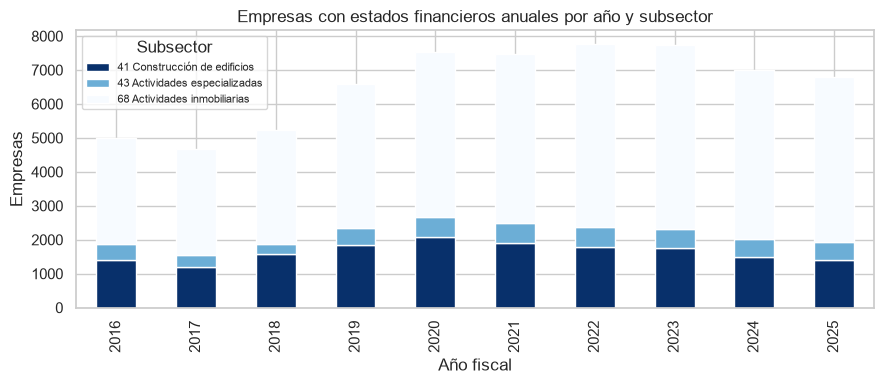

In [2]:
cob = p.groupby(["anio", "ciiu_grupo"]).size().unstack(fill_value=0)
display(cob.assign(total=cob.sum(axis=1)))
ax = cob.plot(kind="bar", stacked=True, figsize=(9, 4), colormap="Blues_r")
ax.set(title="Empresas con estados financieros anuales por año y subsector", xlabel="Año fiscal", ylabel="Empresas")
ax.legend(title="Subsector", fontsize=8)
plt.tight_layout(); plt.savefig(FIG / "eda_01_cobertura.png", dpi=130); plt.show()

In [3]:
# Reportes duplicados: cada empresa puede radicar más de un reporte por año (reexpresiones, correcciones)
ci = ciiu_sector.assign(anio=pd.to_datetime(ciiu_sector.fecha_corte).dt.year)
dup = ci.groupby("anio").agg(reportes=("numero_radicado", "nunique"), empresas=("nit", "nunique"))
dup["reportes_por_empresa"] = (dup.reportes / dup.empresas).round(2)
display(dup)

,reportes,empresas,reportes_por_empresa
anio,,,
2016,5555,5347,1.04
2017,5111,4891,1.04
2018,5643,5420,1.04
2019,7217,6989,1.03
2020,8910,8641,1.03
2021,8475,8214,1.03
2022,8913,8552,1.04
2023,8885,8533,1.04
2024,7965,7711,1.03


In [4]:
clave = ["activos_total", "pasivo_total", "patrimonio", "ingresos", "utilidad_neta", "deuda_financiera",
         "costos_financieros", "utilidad_operacional"]
falt = p[clave].isna().mean().mul(100).round(1).rename("% faltante")
cero = pd.Series({"activos_total <= 0": (p.activos_total <= 0).mean() * 100,
                  "ingresos = 0": (p.ingresos == 0).mean() * 100,
                  "patrimonio < 0": (p.patrimonio < 0).mean() * 100}).round(1).rename("% de empresa-año")
display(falt.to_frame()); display(cero.to_frame())

,% faltante
activos_total,7.0
pasivo_total,7.0
patrimonio,7.0
ingresos,0.8
utilidad_neta,0.0
deuda_financiera,44.6
costos_financieros,30.5
utilidad_operacional,0.0


,% de empresa-año
activos_total <= 0,0.0
ingresos = 0,10.6
patrimonio < 0,2.9


In [5]:
# Rezago de publicación: año del radicado frente al año fiscal
p["anio_radicado"] = p.numero_radicado.str[:4].astype(int)
p["rezago"] = p.anio_radicado - p.anio
display(p.rezago.value_counts(normalize=True).sort_index().mul(100).round(1).rename("% de reportes").to_frame())

,% de reportes
rezago,
1,98.9
2,0.8
3,0.2
4,0.0
5,0.0


## 2. Procesos de insolvencia: cuántos, cuándo y dónde

ciiu_grupo,41 Edificios,42 Obras civiles,43 Especializadas,68 Inmobiliarias,total
anio_apertura,,,,,
2015,2,10,1,1,14
2016,12,13,4,7,36
2017,17,23,4,12,56
2018,29,46,21,28,124
2019,27,51,17,37,132
2020,43,52,18,38,151
2021,25,34,24,22,105
2022,31,38,26,19,114
2023,33,36,30,25,124


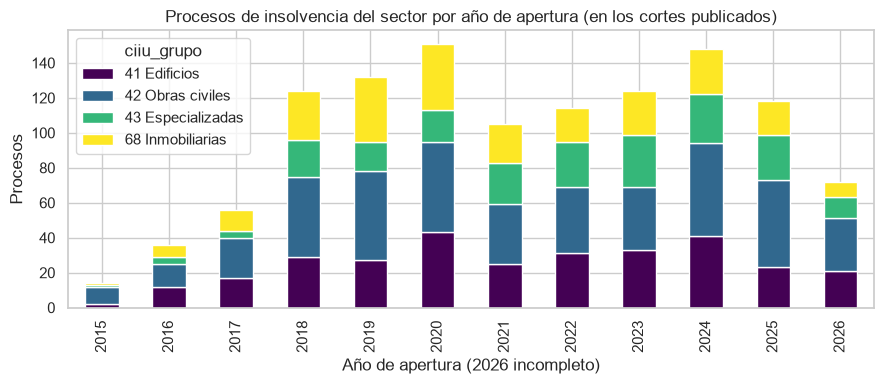

In [6]:
# Sector de cada evento: CIIU de la carátula NIIF si la empresa reporta; si no, el CIIU de la base de insolvencia
ult_ciiu = ciiu_sector.sort_values("numero_radicado").groupby("nit").ciiu.last().str[:3]
ev["grp"] = ev.nit.map(ult_ciiu).fillna(ev.ciiu.astype(str).str[:3])
ev_sec = ev[ev.grp.isin(["F41", "F42", "F43", "L68"])].copy()
ev_sec["ciiu_grupo"] = ev_sec.grp.map({"F41": "41 Edificios", "F42": "42 Obras civiles",
                                       "F43": "43 Especializadas", "L68": "68 Inmobiliarias"})
ev_sec = ev_sec[ev_sec.anio_apertura.between(2015, 2026)]
tab = ev_sec.groupby(["anio_apertura", "ciiu_grupo"]).size().unstack(fill_value=0)
display(tab.assign(total=tab.sum(axis=1)))
ax = tab.plot(kind="bar", stacked=True, figsize=(9, 4), colormap="viridis")
ax.set(title="Procesos de insolvencia del sector por año de apertura (en los cortes publicados)",
       xlabel="Año de apertura (2026 incompleto)", ylabel="Procesos")
plt.tight_layout(); plt.savefig(FIG / "eda_02_eventos.png", dpi=130); plt.show()

In [7]:
# Tipo de proceso (reorganización o liquidación) de los eventos del sector
tipo = ev_sec.proceso.str.upper().str.extract(r"^(REORGANIZ|LIQUIDAC|VALIDAC)")[0].fillna("OTRO")
display(tipo.map({"REORGANIZ": "Reorganización", "LIQUIDAC": "Liquidación", "VALIDAC": "Validación"}).fillna("Otro")
        .value_counts().rename("procesos").to_frame())

,procesos
0,
Reorganización,847
Liquidación,295
Otro,45
Validación,7


In [8]:
# ¿Cuántos eventos tienen estados financieros del año anterior en resumen_empresas?
ult = p_todo.groupby("nit").anio.apply(set)
def tiene_prev(r, k):
    return (r.anio_apertura - k) in ult.get(r.nit, set())
ev_sec["fs_ano_previo"] = ev_sec.apply(lambda r: tiene_prev(r, 1), axis=1)
ev_sec["fs_dos_anos_antes"] = ev_sec.apply(lambda r: tiene_prev(r, 2), axis=1)
ev_sec = ev_sec[ev_sec.anio_apertura.between(2017, 2026)]
res = pd.Series({"Eventos del sector 2017-2026": len(ev_sec),
                 "Con estados financieros del año anterior": int(ev_sec.fs_ano_previo.sum()),
                 "Con estados financieros de dos años antes": int(ev_sec.fs_dos_anos_antes.sum())})
display(res.to_frame("n")); print(f"Cobertura de eventos con FS previos: {ev_sec.fs_ano_previo.mean():.0%}")

,n
Eventos del sector 2017-2026,1144
Con estados financieros del año anterior,433
Con estados financieros de dos años antes,392


Cobertura de eventos con FS previos: 38%


## 3. Variable objetivo: eventos raros y cambio por año

,empresa_anio,eventos,por_mil
anio,,,
2016,4961,14,2.8
2017,4627,35,7.6
2018,5147,28,5.4
2019,6460,49,7.6
2020,7347,20,2.7
2021,7268,25,3.4
2022,7571,23,3.0
2023,7524,28,3.7
2024,6786,15,2.2


Horizonte 1: 57,691 empresa-año, 237 eventos, prevalencia 0.41%
Horizonte 2: 50,905 empresa-año, 226 eventos, prevalencia 0.44%


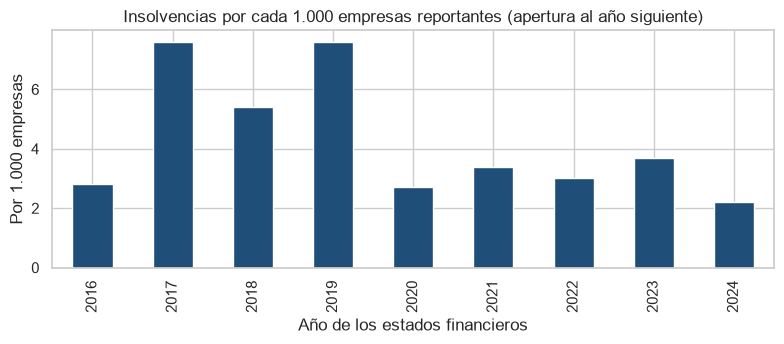

In [9]:
m1 = p[(p.post_evento == 0) & (p.h1_valido == 1)].copy()
m2 = p[(p.post_evento == 0) & (p.h2_valido == 1)].copy()
r1 = m1.groupby("anio").agg(empresa_anio=("nit", "size"), eventos=("y_h1", "sum"))
r1["por_mil"] = (r1.eventos / r1.empresa_anio * 1000).round(1)
display(r1)
print(f"Horizonte 1: {len(m1):,} empresa-año, {int(m1.y_h1.sum())} eventos, prevalencia {m1.y_h1.mean():.2%}")
print(f"Horizonte 2: {len(m2):,} empresa-año, {int(m2.y_h2.sum())} eventos, prevalencia {m2.y_h2.mean():.2%}")
fig, ax = plt.subplots(figsize=(8, 3.6))
r1.por_mil.plot(kind="bar", ax=ax, color="#1f4e79")
ax.set(title="Insolvencias por cada 1.000 empresas reportantes (apertura al año siguiente)",
       xlabel="Año de los estados financieros", ylabel="Por 1.000 empresas")
plt.tight_layout(); plt.savefig(FIG / "eda_03_prevalencia.png", dpi=130); plt.show()

In [10]:
sub = m1.groupby("ciiu_grupo").agg(empresa_anio=("nit", "size"), eventos=("y_h1", "sum"))
sub["por_mil"] = (sub.eventos / sub.empresa_anio * 1000).round(1)
display(sub)

,empresa_anio,eventos,por_mil
ciiu_grupo,,,
41 Construcción de edificios,14526,114,7.8
43 Actividades especializadas,4197,48,11.4
68 Actividades inmobiliarias,38968,75,1.9


## 4. Razones financieras: empresas que luego entran en insolvencia frente al resto

In [11]:
razones = ["liquidez_corriente", "endeudamiento", "apalancamiento", "deuda_fin_activos", "roa",
           "margen_operacional", "cobertura_intereses", "efectivo_activos", "capital_trabajo_activos",
           "ganancias_acum_activos", "ln_activos", "altman_z2"]
etq = {"liquidez_corriente": "Liquidez corriente", "endeudamiento": "Endeudamiento", "apalancamiento": "Apalancamiento",
       "deuda_fin_activos": "Deuda financiera / activos", "roa": "ROA", "margen_operacional": "Margen operacional",
       "cobertura_intereses": "Cobertura de intereses", "efectivo_activos": "Efectivo / activos",
       "capital_trabajo_activos": "Capital de trabajo / activos", "ganancias_acum_activos": "Ganancias acum. / activos",
       "ln_activos": "ln(activos)", "altman_z2": "Z'' de Altman"}

def wins(s):
    lo, hi = s.quantile([.01, .99]); return s.clip(lo, hi)

base = m1[m1.activos_total > 0].copy()
filas = []
for r in razones:
    d = base[[r, "y_h1"]].dropna()
    if d.y_h1.nunique() < 2: continue
    auc = roc_auc_score(d.y_h1, d[r])
    filas.append({"razón": etq[r], "mediana sanas": d[d.y_h1 == 0][r].median(),
                  "mediana insolventes": d[d.y_h1 == 1][r].median(), "AUC univariada": round(auc, 3),
                  "poder (|AUC-0,5|)": round(abs(auc - .5), 3), "n": len(d)})
tabla_r = pd.DataFrame(filas).sort_values("poder (|AUC-0,5|)", ascending=False)
display(tabla_r.round(3).reset_index(drop=True))

,razón,mediana sanas,mediana insolventes,AUC univariada,"poder (|AUC-0,5|)",n
0,Endeudamiento,0.347,0.715,0.721,0.221,53100
1,Efectivo / activos,0.015,0.001,0.281,0.219,53035
2,Z'' de Altman,8.583,5.810,0.326,0.174,52282
3,ROA,0.010,-0.003,0.327,0.173,53092
4,Deuda financiera / activos,0.122,0.395,0.668,0.168,29091
5,Ganancias acum. / activos,0.205,0.052,0.340,0.160,52955
6,Margen operacional,0.150,0.040,0.342,0.158,46949
7,Cobertura de intereses,3.034,0.787,0.350,0.150,33465
8,ln(activos),16.300,16.899,0.639,0.139,53100
9,Apalancamiento,0.468,1.460,0.620,0.120,53100


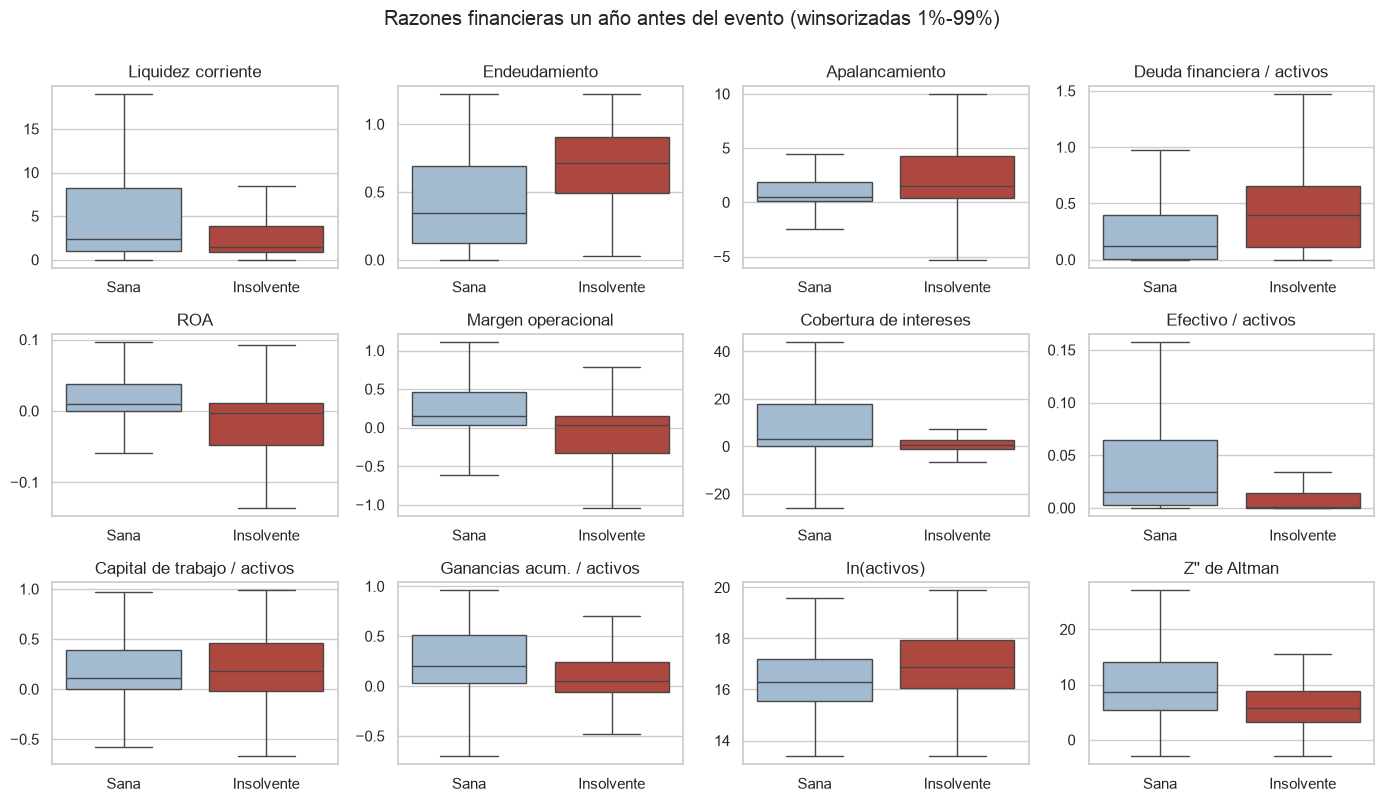

In [12]:
fig, axs = plt.subplots(3, 4, figsize=(14, 8))
for ax, r in zip(axs.ravel(), razones):
    d = base[[r, "y_h1"]].dropna().copy(); d[r] = wins(d[r]); d["Clase"] = d.y_h1.map({0: "Sana", 1: "Insolvente"})
    sns.boxplot(data=d, x="Clase", y=r, hue="Clase", ax=ax, palette=["#9bbbd9", "#c0392b"], showfliers=False, legend=False)
    ax.set(title=etq[r], xlabel="", ylabel="")
plt.suptitle("Razones financieras un año antes del evento (winsorizadas 1%-99%)", y=1.0)
plt.tight_layout(); plt.savefig(FIG / "eda_04_razones.png", dpi=130); plt.show()

## 5. Línea base: ¿qué tanto anticipa el Z'' de Altman?

Se replica la ventana de prueba de la Guía de planteamiento (estados financieros 2022-2024) y se mide, al
revisar el 10 % de las empresas con peor puntaje, el porcentaje de eventos y de deuda financiera anticipados.

In [13]:
def captura(d, score_col, ascendente, frac=.10, y="y_h1"):
    d = d.dropna(subset=[score_col]).copy()
    d["deuda"] = d.deuda_financiera.fillna(0).clip(lower=0)
    corte = d[score_col].quantile(frac if ascendente else 1 - frac)
    top = d[d[score_col] <= corte] if ascendente else d[d[score_col] >= corte]
    ev_ = d[d[y] == 1]; ev_top = top[top[y] == 1]
    return {"n": len(d), "eventos": int(len(ev_)), "AUC": round(roc_auc_score(d[y], -d[score_col] if ascendente else d[score_col]), 3),
            "% eventos con alerta": round(len(ev_top) / max(len(ev_), 1) * 100, 1),
            "% deuda anticipada": round(ev_top.deuda.sum() / max(ev_.deuda.sum(), 1) * 100, 1),
            "alertas por evento": round(len(top) / max(len(ev_top), 1), 1),
            "lift (x tasa base)": round((len(ev_top) / len(top)) / (len(ev_) / len(d)), 1)}

ventana = m1[(m1.anio.between(2022, 2024)) & (m1.activos_total > 0)]
sal = pd.DataFrame({
    "Z'' de Altman (menor = más riesgo)": captura(ventana, "altman_z2", True),
    "Endeudamiento (mayor = más riesgo)": captura(ventana, "endeudamiento", False),
    "Deuda financiera / activos": captura(ventana, "deuda_fin_activos", False),
}).T
display(sal)
tot = ventana[ventana.y_h1 == 1].deuda_financiera.fillna(0).sort_values(ascending=False)
print(f"Concentración: las 3 empresas con más deuda explican {tot.head(3).sum() / max(tot.sum(), 1):.0%} "
      f"de la deuda financiera de los {len(tot)} eventos de la ventana.")

,n,eventos,AUC,% eventos con alerta,% deuda anticipada,alertas por evento,lift (x tasa base)
Z'' de Altman (menor = más riesgo),21487.0,66.0,0.675,16.7,23.1,195.4,1.7
Endeudamiento (mayor = más riesgo),21880.0,66.0,0.755,27.3,26.8,121.6,2.7
Deuda financiera / activos,11129.0,55.0,0.707,20.0,25.8,101.2,2.0


Concentración: las 3 empresas con más deuda explican 42% de la deuda financiera de los 66 eventos de la ventana.


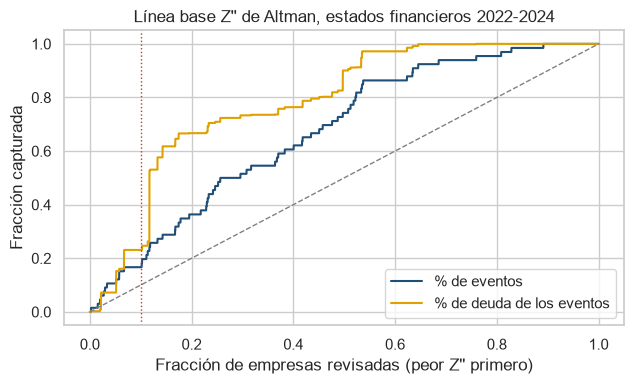

In [14]:
# Curva de captura (eventos y deuda) según la capacidad de revisión, para la línea base de Altman
d = ventana.dropna(subset=["altman_z2"]).sort_values("altman_z2").reset_index(drop=True)
d["deuda"] = d.deuda_financiera.fillna(0).clip(lower=0)
x = np.arange(1, len(d) + 1) / len(d)
ce = d.y_h1.cumsum() / max(d.y_h1.sum(), 1)
cd = (d.y_h1 * d.deuda).cumsum() / max((d.y_h1 * d.deuda).sum(), 1)
fig, ax = plt.subplots(figsize=(6.5, 4))
ax.plot(x, ce, label="% de eventos", color="#1f4e79"); ax.plot(x, cd, label="% de deuda de los eventos", color="#e0a100")
ax.plot([0, 1], [0, 1], "--", color="gray", lw=1); ax.axvline(.10, color="#c0392b", lw=1, ls=":")
ax.set(xlabel="Fracción de empresas revisadas (peor Z'' primero)", ylabel="Fracción capturada",
       title="Línea base Z'' de Altman, estados financieros 2022-2024")
ax.legend(); plt.tight_layout(); plt.savefig(FIG / "eda_05_altman.png", dpi=130); plt.show()

## 6. Partición temporal

El modelo se evalúa siempre en años posteriores a los de entrenamiento (origen móvil). Como los estados financieros
del año `s` se publican hacia mediados de `s+1`, al momento de decidir ya se conoce la apertura de procesos hasta
`s`. Por eso, con horizonte de un año se entrena hasta el año fiscal `s-1` y con horizonte de dos años hasta `s-2`
(purga): así ninguna etiqueta de entrenamiento depende de eventos que aún no habían ocurrido.

In [15]:
filas = []
for h, y, valido, rezago_h in [("1 año", "y_h1", "h1_valido", 1), ("2 años", "y_h2", "h2_valido", 2)]:
    base_h = p[(p.post_evento == 0) & (p[valido] == 1)]
    for s in range(2019, 2025):
        tr, te = base_h[base_h.anio <= s - rezago_h], base_h[base_h.anio == s]
        if len(te) == 0 or int(te[y].sum()) == 0:
            continue
        filas.append({"horizonte": h, "año de prueba": s, "entrenamiento hasta": s - rezago_h,
                      "empresa-año entrenamiento": len(tr), "eventos entrenamiento": int(tr[y].sum()),
                      "empresa-año prueba": len(te), "eventos prueba": int(te[y].sum())})
origen = pd.DataFrame(filas)
display(origen)

,horizonte,año de prueba,entrenamiento hasta,empresa-año entrenamiento,eventos entrenamiento,empresa-año prueba,eventos prueba
0,1 año,2019,2018,14735,77,6460,49
1,1 año,2020,2019,21195,126,7347,20
2,1 año,2021,2020,28542,146,7268,25
3,1 año,2022,2021,35810,171,7571,23
4,1 año,2023,2022,43381,194,7524,28
5,1 año,2024,2023,50905,222,6786,15
6,2 años,2019,2017,9588,59,6460,20
7,2 años,2020,2018,14735,97,7347,27
8,2 años,2021,2019,21195,117,7268,26
9,2 años,2022,2020,28542,144,7571,38


In [16]:
# Partición propuesta para el desarrollo (horizonte de un año)
corte = pd.cut(m1.anio, [2015, 2021, 2022, 2025], labels=["entrenamiento 2016-2021", "validación 2022", "prueba 2023-2024"])
part = m1.groupby(corte, observed=True).agg(empresa_anio=("nit", "size"), empresas=("nit", "nunique"),
                                            eventos=("y_h1", "sum"), prevalencia=("y_h1", "mean"))
part["prevalencia"] = (part.prevalencia * 100).round(2)
display(part)
nits_ent = set(m1[m1.anio <= 2021].nit)
prueba = m1[m1.anio >= 2023]
print(f"Empresas de la prueba que ya aparecen en el entrenamiento: {prueba.nit.isin(nits_ent).mean():.0%} "
      "(las observaciones de una misma empresa no son independientes: los intervalos se calculan remuestreando empresas).")

,empresa_anio,empresas,eventos,prevalencia
anio,,,,
entrenamiento 2016-2021,35810,9367,171,0.48
validación 2022,7571,7571,23,0.3
prueba 2023-2024,14310,7584,43,0.3


Empresas de la prueba que ya aparecen en el entrenamiento: 91% (las observaciones de una misma empresa no son independientes: los intervalos se calculan remuestreando empresas).


## 7. Chequeo de fuga de información

In [17]:
PROHIBIDAS = {"anio_apertura", "proceso", "post_evento", "y_h1", "y_h2", "h1_valido", "h2_valido"}
FEATURES = razones + ["patrimonio_negativo", "perdida_neta"]
pos = m1[m1.y_h1 == 1]
chequeos = pd.DataFrame([
    ("Una fila por empresa-año", not p.duplicated(["nit", "anio"]).any()),
    ("El conjunto modelable no incluye años posteriores a la apertura", int((m1.anio >= m1.anio_apertura).sum()) == 0),
    ("Todo positivo del horizonte 1 abre el proceso en el año siguiente", bool((pos.anio_apertura == pos.anio + 1).all())),
    ("Ninguna variable explicativa usa la apertura ni la etiqueta", not (PROHIBIDAS & set(FEATURES))),
    ("Las variables explicativas vienen de estados financieros con corte a 31 de diciembre del año fiscal", True),
], columns=["chequeo", "cumple"])
display(chequeos)
print(f"Empresa-año excluidas por ser posteriores a la apertura: {int((p.post_evento == 1).sum()):,}")

,chequeo,cumple
0,Una fila por empresa-año,True
1,El conjunto modelable no incluye años posterio...,True
2,Todo positivo del horizonte 1 abre el proceso ...,True
3,Ninguna variable explicativa usa la apertura n...,True
4,Las variables explicativas vienen de estados f...,True


Empresa-año excluidas por ser posteriores a la apertura: 1,554


In [18]:
# Señales de fuga: ninguna variable debería separar casi perfectamente, el año solo no debe predecir
auc_max = tabla_r["AUC univariada"].sub(0.5).abs().max() + 0.5
print(f"Mayor AUC univariada: {auc_max:.2f} (un valor cercano a 1 sugeriría fuga)")
print(f"AUC del año fiscal como único predictor: {roc_auc_score(m1.y_h1, m1.anio):.2f} (cercano a 0,5 = sin efecto de calendario)")
comp = []
for r in ["endeudamiento", "efectivo_activos", "altman_z2", "roa"]:
    d1 = m1[m1.activos_total > 0][[r, "y_h1"]].dropna(); d2 = m2[m2.activos_total > 0][[r, "y_h2"]].dropna()
    comp.append({"variable": etq[r], "AUC horizonte 1 año": round(roc_auc_score(d1.y_h1, d1[r]), 3),
                 "AUC horizonte 2 años": round(roc_auc_score(d2.y_h2, d2[r]), 3)})
display(pd.DataFrame(comp))
falt_clase = (m1.groupby("y_h1")[razones].apply(lambda g: g.isna().mean() * 100).T.round(1)
              .rename(columns={0: "% faltante sanas", 1: "% faltante insolventes"}))
display(falt_clase)

Mayor AUC univariada: 0.72 (un valor cercano a 1 sugeriría fuga)
AUC del año fiscal como único predictor: 0.43 (cercano a 0,5 = sin efecto de calendario)


,variable,AUC horizonte 1 año,AUC horizonte 2 años
0,Endeudamiento,0.721,0.712
1,Efectivo / activos,0.281,0.367
2,Z'' de Altman,0.326,0.361
3,ROA,0.327,0.398


y_h1,% faltante sanas,% faltante insolventes
liquidez_corriente,9.3,15.2
endeudamiento,7.9,14.8
apalancamiento,7.9,14.8
deuda_fin_activos,49.7,28.7
roa,7.9,14.8
margen_operacional,11.5,8.0
cobertura_intereses,36.9,36.3
efectivo_activos,8.0,14.8
capital_trabajo_activos,8.9,15.2
ganancias_acum_activos,8.2,14.8


## 8. ¿Son alcanzables las metas de negocio con este universo?

Con capacidad de revisión del 10 %, las alertas por evento valen `0,10 / (recall x prevalencia)`. Incluso un
modelo perfecto (recall = 100 %) tendría `0,10 / prevalencia` alertas por evento.

In [19]:
prev_v = ventana.y_h1.mean()
tab_m = pd.DataFrame({
    "prevalencia (ventana 2022-2024)": [f"{prev_v:.2%}"],
    "alertas por evento con un modelo perfecto": [round(0.10 / prev_v, 1)],
    "meta de la Guía (máximo)": [32],
    "prevalencia mínima para cumplirla con recall 100 %": [f"{0.10 / 32:.2%}"],
})
display(tab_m.T.rename(columns={0: "valor"}))
sub_v = ventana.groupby("ciiu_grupo").agg(empresa_anio=("nit", "size"), eventos=("y_h1", "sum"))
sub_v["prevalencia %"] = (sub_v.eventos / sub_v.empresa_anio * 100).round(2)
sub_v["participación en empresa-año %"] = (sub_v.empresa_anio / sub_v.empresa_anio.sum() * 100).round(1)
sub_v["participación en eventos %"] = (sub_v.eventos / sub_v.eventos.sum() * 100).round(1)
display(sub_v)

,valor
prevalencia (ventana 2022-2024),0.30%
alertas por evento con un modelo perfecto,33.2
meta de la Guía (máximo),32
prevalencia mínima para cumplirla con recall 100 %,0.31%


,empresa_anio,eventos,prevalencia %,participación en empresa-año %,participación en eventos %
ciiu_grupo,,,,,
41 Construcción de edificios,4802,31,0.65,21.9,47.0
43 Actividades especializadas,1545,12,0.78,7.1,18.2
68 Actividades inmobiliarias,15533,23,0.15,71.0,34.8


## 9. Hallazgos y efecto en el diseño

1. **Cobertura estable y reportes limpios.** Desde 2019 hay entre 6.500 y 7.800 empresas por año en el universo
   principal, con 1,03 a 1,04 reportes por empresa. El 98,9 % de los estados financieros se radica al año siguiente,
   por lo que una apertura "en el año siguiente" puede ocurrir antes de que se publiquen; el horizonte de dos años
   es el operativo, como ya anticipaba el planteamiento.
2. **Evento raro.** La prevalencia es 0,41 % a un año (237 eventos en 57.691 empresa-año) y 0,44 % a dos años. La tasa
   por mil empresas pasó de 7,6 en 2017 y 2019 a 2,2 en 2024, así que la prevalencia depende de la ventana.
3. **El riesgo no es homogéneo.** Edificios (7,8 por mil) y actividades especializadas (11,4 por mil) concentran los eventos;
   las inmobiliarias son el 68 % de las empresa-año pero solo 1,9 por mil. La lista debe poder filtrarse por subsector.
4. **Muchas insolvencias no tienen estados financieros previos.** Solo el 38 % de los eventos del sector (433 de 1.144)
   tiene estados financieros del año anterior. La ausencia de reporte reciente debe mostrarse en el tablero como señal.
5. **Razones que separan.** Endeudamiento (mediana 0,72 frente a 0,35), efectivo sobre activos, Z'' de Altman, ROA y deuda
   financiera sobre activos son las que más discriminan. Las empresas que luego entran en insolvencia son más grandes
   (ln activos 16,9 frente a 16,3): el tamaño no protege.
6. **Línea base débil.** El Z'' de Altman sin reentrenar logra AUC 0,68 y, al revisar el 10 %, anticipa 16,7 % de los eventos y
   23,1 % de la deuda; el endeudamiento solo es mejor (AUC 0,76). Tres empresas explican el 42 % de la deuda de los
   eventos de la ventana, de modo que la métrica de deuda anticipada es frágil y se reportará con intervalos.
7. **Las metas deben reformularse.** Con esta prevalencia, ni un modelo perfecto cumpliría "máximo 32 alertas por evento".
   Se propone expresar la carga como lift sobre la tasa base y fijar la meta de anticipación frente al endeudamiento y el Z''.
   Los resultados preliminares de la Guía no se reproducen con el universo completo y se tratan como no verificados.
8. **Partición temporal.** Se propone entrenar con los años fiscales 2016-2021 (35.810 empresa-año, 171 eventos),
   validar con 2022 (7.571 y 23 eventos) y probar con 2023-2024 (14.310 y 43 eventos). Con eventos tan escasos se usará
   además validación de origen móvil. El 91 % de las empresas de la prueba ya está en el entrenamiento, por lo que los
   intervalos se calculan remuestreando empresas y no filas.
9. **No se detectó fuga de información.** Pasan los cinco chequeos (una fila por empresa-año, sin años posteriores a la
   apertura, positivos con apertura en el año siguiente, sin variables derivadas de la apertura y razones de estados con
   corte a 31 de diciembre). La mayor AUC univariada es 0,72, y las AUC a uno y dos años son parecidas (endeudamiento 0,72
   y 0,71), lo que descarta que el horizonte de un año esté inflado por estados radicados después de la apertura.
   Quedan dos advertencias: el año fiscal solo logra AUC 0,43 (la tasa de eventos baja con el calendario, hay deriva) y la
   ausencia de datos es informativa (falta el balance en 14,8 % de las insolventes frente a 7,9 % de las sanas), así que
   se modelará con indicadores de faltante.